In [1]:
import sys
!{sys.executable} -m pip install -q pandas matplotlib

# 05. People and places: who lives where, and how that is changing

China has about 1.4 billion people, but they are not spread evenly. One province, Guangdong, has more people than most countries. The west is vast and empty by comparison. This notebook covers population distribution, aging, urbanization, regional economies, ethnic composition from the 2020 census, and religion, where the numbers depend heavily on who is asking.

## The national picture

The 7th National Population Census, conducted in late 2020 and released May 11, 2021, counted 1,411.78 million people on the mainland. By the end of 2025, the NBS put the total at 1,404.89 million, down 3.39 million on the year, the fourth straight annual fall. The urban resident population in 2025 was 953.80 million, an urbanization rate of 67.89 percent, up 0.89 points on 2024. The population aged 16 to 59 was 851.36 million, 60.6 percent of the total.

Births were 7.92 million in 2025 (a rate of 5.63 per thousand) and deaths were 11.31 million (8.04 per thousand), a natural growth rate of minus 2.41 per thousand. The birth rate is the lowest since 1949, and the death rate is the highest since 1968. Those two facts together explain why the population is shrinking.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.figsize"] = (10, 5.5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
PROC = "../data/processed"
CHARTS = "../charts"

prov = pd.read_csv(f"{PROC}/provinces.csv")
reg = prov.groupby("region").agg(gdp=("gdp_2024_m_cny", "sum"),
                                  pop=("pop_mid2022", "sum"),
                                  urban=("urban_pop_mid2022", "sum"))
reg["urban_rate"] = (reg["urban"] / reg["pop"] * 100).round(1)
reg = reg.sort_values("gdp", ascending=False)
print(reg.to_string())
print()
print("East region share of provincial GDP:",
      round(reg.loc["East", "gdp"] / reg["gdp"].sum() * 100, 1), "percent")
print("Northeast share:", round(reg.loc["Northeast", "gdp"] / reg["gdp"].sum() * 100, 1), "percent")


                    gdp        pop      urban  urban_rate
region                                                   
East           52122150  425730000  293670000        69.0
South Central  35444180  413393000  263000000        63.6
North          16674010  168490000  115210000        68.4
Southwest      15344280  205000000  118430000        57.8
Northwest       7843570  103580000   62300000        60.1
Northeast       6332390   96440000   66120000        68.6

East region share of provincial GDP: 39.0 percent
Northeast share: 4.7 percent


saved 05_regional_gdp.png


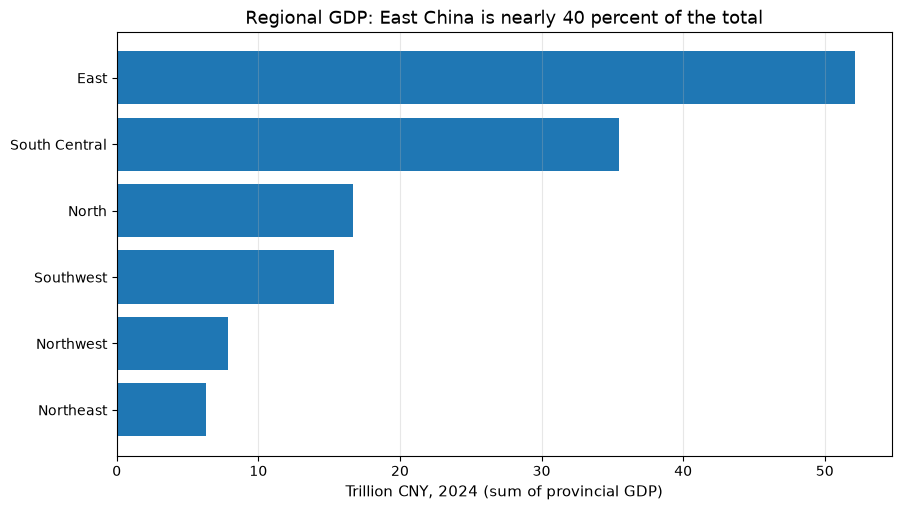

In [3]:

fig, ax = plt.subplots(figsize=(10, 5.5))
r = reg.sort_values("gdp")
ax.barh(r.index, r.gdp / 1e6)
ax.set_xlabel("Trillion CNY, 2024 (sum of provincial GDP)")
ax.set_title("Regional GDP: East China is nearly 40 percent of the total")
ax.grid(True, axis="x", alpha=0.3)
plt.savefig(f"{CHARTS}/05_regional_gdp.png", dpi=150, bbox_inches="tight")
print("saved 05_regional_gdp.png")


## Regions in words

East China (Shanghai, Jiangsu, Zhejiang, Anhui, Fujian, Jiangxi, Shandong) is the economic core: about 52.1 trillion yuan in 2024, nearly 40 percent of the provincial total. South Central China (Henan, Hubei, Hunan, Guangdong, Guangxi, Hainan) is second at about 35.4 trillion, carried by Guangdong. The North (Beijing, Tianjin, Hebei, Shanxi, Inner Mongolia) and Southwest (Chongqing, Sichuan, Guizhou, Yunnan, Tibet) are each around 15 to 17 trillion. The Northwest is about 7.8 trillion and the Northeast, once the industrial base, is last at about 6.3 trillion, with the slowest growth and a shrinking population.

The population map tells the same story from the other side. Guangdong had 126.01 million people in the 2020 census, Shandong 101.53 million, Henan 99.37 million. Tibet had 3.65 million, Qinghai 5.92 million, Ningxia 7.20 million. The east is crowded and rich. The west is spacious and poorer. Every plan since the 10th has promised to narrow that gap, and the gap is still there.

                        group  population  share_pct
                          Han  1286310000      91.11
                       Zhuang    19568546       1.39
                       Uyghur    11774538       0.84
                          Hui    11377914       0.81
                         Miao    11067929       0.79
                       Manchu    10423303       0.74
All other minorities combined    61257770       4.34
shares are the census bulletin's published rounded figures, so they sum to about 100
saved 05_ethnic.png


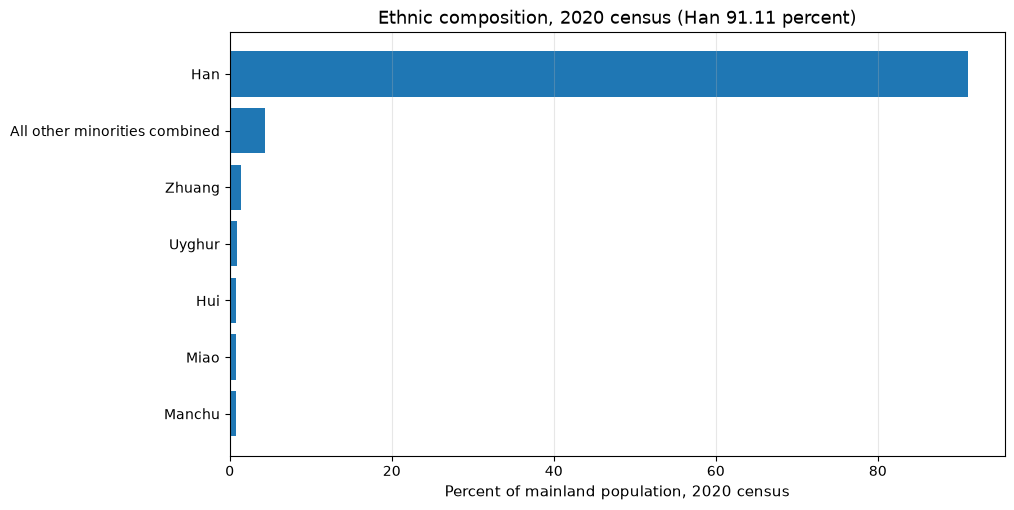

In [4]:

eth = pd.read_csv(f"{PROC}/ethnic_2020.csv")
fig, ax = plt.subplots(figsize=(10, 5.5))
e = eth.sort_values("share_pct", ascending=True)
ax.barh(e.group, e.share_pct)
ax.set_xlabel("Percent of mainland population, 2020 census")
ax.set_title("Ethnic composition, 2020 census (Han 91.11 percent)")
ax.grid(True, axis="x", alpha=0.3)
plt.savefig(f"{CHARTS}/05_ethnic.png", dpi=150, bbox_inches="tight")
print(eth.to_string(index=False))
print("shares are the census bulletin's published rounded figures, so they sum to about 100")
print("saved 05_ethnic.png")


## Ethnic composition: what the census says

The 2020 census counted 1,286.31 million Han people, 91.11 percent of the mainland population, and 125.47 million people from ethnic minorities, 8.89 percent. The largest minority groups are the Zhuang (19.57 million, 1.39 percent), Uyghur (11.77 million, 0.84 percent), Hui (11.38 million, 0.81 percent), Miao (11.07 million, 0.79 percent), and Manchu (10.42 million, 0.74 percent). The remaining minorities together are 61.26 million people, 4.34 percent.

Two notes. First, the census asks about ethnicity, and these are self-reported census categories, not estimates. Second, minorities are concentrated in the west and south: Xinjiang, Tibet, Inner Mongolia, Guangxi, Ningxia, and Yunnan have large minority shares, which is part of why regional policy and ethnic policy overlap.

## Religion: why the numbers disagree so much

The census does not ask about religion. Every religion figure for China is therefore a survey or administrative estimate, and the estimates differ wildly because they measure different things: belief, practice, affiliation, registered membership, and folk religion overlap. The chart below puts three published estimates side by side. Do not read any one of them as the true figure.

- Pew Research Center (2023, self-identified affiliation): no religion 93.0 percent, Buddhism 3.7 percent, Christianity 1.4 percent, Islam 1.3 percent, folk beliefs 0.2 percent. This counts people who name a religion when asked.
- CIA World Factbook (2021, among people claiming a belief): unaffiliated 52.1 percent, folk beliefs 21.9 percent, Buddhism 18.2 percent, Christianity 5.1 percent, Islam 1.8 percent. This counts folk religion and belief more broadly, so the religious shares look much larger.
- China Social Survey (2010): ancestor and god cults 56.2 percent, Buddhism 13.8 percent, Taoist folk religions 12.9 percent, Christianity 2.4 percent, Islam 1.7 percent, Taoism 0.9 percent. This counts practice and folk belief, which overlap heavily.

The government formally recognizes five religions: Buddhism, Taoism, Islam, Catholicism, and Protestantism. The official Christian count is about 44 million (38 million Protestant plus 6 million Catholic, as of 2018 in secondary summaries), while independent estimates that include unregistered house churches put the total at 70 to 100 million or higher by 2024. The gap between the official and independent counts is itself the story: registration, not belief, is what the official number measures.

saved 05_religion.png


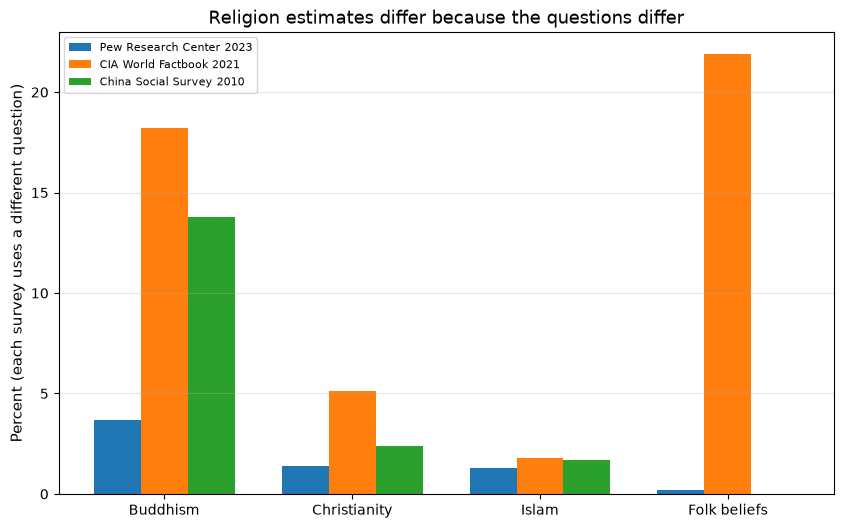

In [5]:

rel = pd.read_csv(f"{PROC}/religion_estimates.csv")
fig, ax = plt.subplots(figsize=(10, 6))
groups = ["Buddhism", "Christianity", "Islam", "Folk beliefs"]
sources = ["Pew Research Center 2023, self-identified",
           "CIA World Factbook 2021, among people claiming a belief",
           "China Social Survey 2010"]
import numpy as np
x = np.arange(len(groups))
width = 0.25
for i, src in enumerate(sources):
    vals = []
    for gname in groups:
        hit = rel[(rel.source == src) & (rel.group == gname)]
        vals.append(hit.share_pct.iloc[0] if len(hit) else 0)
    ax.bar(x + (i - 1) * width, vals, width, label=src.split(",")[0])
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.set_ylabel("Percent (each survey uses a different question)")
ax.set_title("Religion estimates differ because the questions differ")
ax.legend(fontsize=8)
ax.grid(True, axis="y", alpha=0.3)
plt.savefig(f"{CHARTS}/05_religion.png", dpi=150, bbox_inches="tight")
print("saved 05_religion.png")


65 and over, 2024: 14.665268836569
0 to 14, 2024: 16.0078123326803
saved 05_age_structure.png


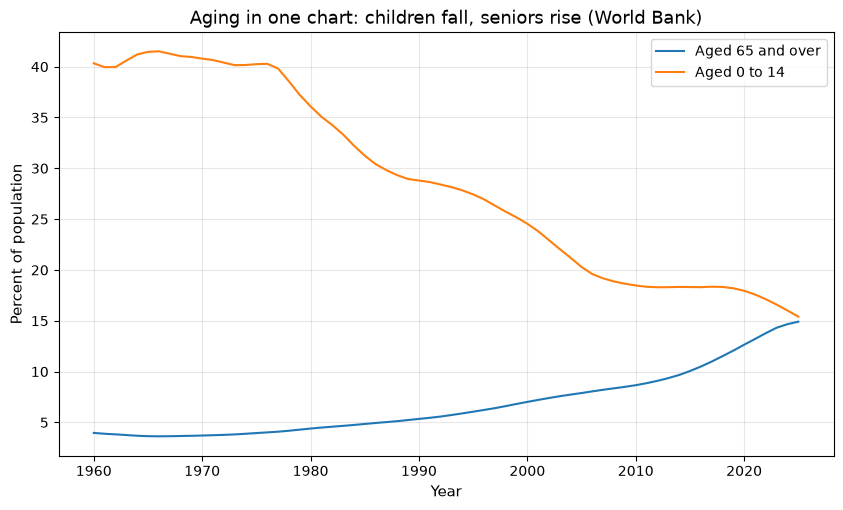

In [6]:

fig, ax = plt.subplots()
wb = pd.read_csv(f"{PROC}/wb_longrun.csv")
a = wb.dropna(subset=["pop_65_pct", "pop_0_14_pct"])
ax.plot(a.year, a.pop_65_pct, label="Aged 65 and over")
ax.plot(a.year, a.pop_0_14_pct, label="Aged 0 to 14")
ax.set_ylabel("Percent of population")
ax.set_xlabel("Year")
ax.set_title("Aging in one chart: children fall, seniors rise (World Bank)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.savefig(f"{CHARTS}/05_age_structure.png", dpi=150, bbox_inches="tight")
print("65 and over, 2024:", a[a.year == 2024].pop_65_pct.iloc[0])
print("0 to 14, 2024:", a[a.year == 2024].pop_0_14_pct.iloc[0])
print("saved 05_age_structure.png")


## Aging: the slow change that matters most

The age chart is the most important chart in this notebook. The share of children falls steadily from the 1970s onward, and the share of seniors rises steadily from the 2000s onward. The two lines are heading toward each other. An economy with fewer young workers and more retirees grows more slowly, spends more on pensions and health care, and needs higher productivity from each worker just to stand still. That is the demographic headwind the 15th plan has to plan around, and it is why the plan puts 7 of its 20 indicators on livelihood and well-being.

Next: notebook 06 looks at what the 15th plan aims at, and what to watch.